# A detailed analysis of one balloon segment

Author: Brian Green (briangre@stanford.edu)

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

from matplotlib.dates import DateFormatter

### Constants

In [1]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 0.5 # (minutes) the time step of the interpolated data

# Set the GW period range
GW_PERIOD_MIN = 10     # (minutes) the minimum period for GW packets is the maximum of this and the buoyancy period
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum period for GW packets is the minimum of this and the Coriolis period

# Parameters for identifying and quantifying maxima in the total momentum flux wavelet
STENCIL_DIM = 3 # (must be an odd number) the size of the stencil for averaging quantities near the momentum flux
                # maximum. The stencil has a size STENCIL_DIM x STENCIL_DIM wavelet coefficients, centered on the maximum
FLUX_THRESHOLD = 50 # (mPa) the threshold of the frequency-integrated total momentum flux to look identify times
                    # to look for maxima

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Load in the data

In [3]:
flights = pd.read_feather('../../processing/Concordiasi_with_ERA5_5_interpolated.feather')

## Select just the flights that start in 2014
#flight_time_start = flights.groupby('flight_id').apply(lambda f: f.time.iloc[0])
#flight_ids = flight_time_start[flight_time_start < pd.Timestamp('2015-01-01 00:00:00')]
#flight_ids = flight_ids[flight_ids >= pd.Timestamp('2014-01-01 00:00:00')]
#flights = flights[flights.flight_id.isin(flight_ids.index)]

# Select segments with a specified length
min_length = pd.Timedelta('14 days')
#max_length = pd.Timedelta('4 days')
segments_to_select = flights.groupby('segment_id').apply(lambda f: f.time.iloc[-1] - f.time.iloc[0])
segments_to_select = segments_to_select[segments_to_select > min_length]
#segments_to_select = segments_to_select[segments_to_select < max_length]
flights = flights[flights.segment_id.isin(segments_to_select.index)]

## Select segments with time-mean latitude within in a latitude band
#lat_band_min = -10
#lat_band_max = 10
#segments_to_select = flights.groupby('segment_id').apply(lambda f: f.latitude.mean())
#segments_to_select = segments_to_select[segments_to_select >= lat_band_min]
#segments_to_select = segments_to_select[segments_to_select < lat_band_max]
#flights = flights[flights.segment_id.isin(segments_to_select.index)]

## Select segments that fly inside a lat/lon box
## North Africa:
#lat_box_min = 15
#lat_box_max = 30
#lon_box_min = -10
#lon_box_max = 20
#lon_weighting = 1 # see the explanation for the Pacific
## Andes:
#lat_box_min = -55
#lat_box_max = -30
#lon_box_min = -80
#lon_box_max = -60
#lon_weighting = 1 # see the explanation for the Pacific
### Tropical Pacific
##lat_box_min = -5
##lat_box_max = 15
##lon_box_min = 150
##lon_box_max = -90
##lon_weighting = 2 # to deal with the date line
#flights[['in_box1','in_box2','in_box3','in_box4']] = 0
#flights.loc[flights.latitude >= lat_box_min, 'in_box1'] = 1
#flights.loc[flights.latitude < lat_box_max, 'in_box2'] = 1
#flights.loc[flights.longitude >= lon_box_min, 'in_box3'] = 1*lon_weighting
#flights.loc[flights.longitude < lon_box_max, 'in_box4'] = 1*lon_weighting
#flights['in_box'] = flights.in_box1 + flights.in_box2 + flights.in_box3 + flights.in_box4
#segments_to_select = flights[flights.in_box == 4].segment_id.unique()
#flights = flights[flights.segment_id.isin(segments_to_select)]
#flights = flights.drop(columns=['in_box1','in_box2','in_box3','in_box4','in_box'])

print('Number of candidate segments:', flights.segment_id.nunique())
print('')
print('Segment IDs:', flights.segment_id.unique())
print('')
print('Flight IDs:', flights.flight_id.unique())
flights

Number of candidate segments: 15

Segment IDs: [  0   4   5  17  18  21  39  44  52  64 127 147 156 157 165]

Flight IDs: ['01' '03' '04' '06' '07' '10' '14' '17' '18' '19']


,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_ERA5,N2_ERA5,superpressure,segment_id
0,01,2010-09-23 01:35:00,-78.406868,168.230804,17418.7,61.573,8.44,-9.58,192.615719,0.000580,7.54,0
1,01,2010-09-23 01:35:30,-78.409485,168.242310,17415.3,61.616,8.36,-9.75,192.613123,0.000580,7.70,0
2,01,2010-09-23 01:36:00,-78.412132,168.253815,17408.5,61.715,8.37,-9.82,192.607186,0.000579,7.83,0
3,01,2010-09-23 01:36:30,-78.414772,168.265289,17403.8,61.751,8.40,-9.79,192.605042,0.000579,7.97,0
4,01,2010-09-23 01:37:00,-78.417358,168.276642,17405.5,61.691,8.43,-9.68,192.608620,0.000579,8.11,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2333056,19,2010-11-04 23:47:30,-66.672211,84.015633,17457.2,68.989,30.15,18.33,213.847393,0.000641,8.97,165
2333057,19,2010-11-04 23:48:00,-66.667274,84.036118,17458.7,68.975,30.26,18.36,213.851416,0.000641,8.99,165
2333058,19,2010-11-04 23:48:30,-66.662323,84.056686,17459.6,68.984,30.38,18.39,213.848829,0.000641,9.00,165
2333059,19,2010-11-04 23:49:00,-66.657372,84.077339,17460.1,68.995,30.49,18.42,213.845669,0.000641,9.01,165


In [39]:
segments_to_select

segment_id
0    23 days 10:04:00
4    14 days 14:29:00
8    43 days 04:16:30
9    27 days 09:32:30
10   75 days 10:02:00
12   21 days 10:59:00
13   25 days 07:29:00
14   19 days 17:59:00
18   19 days 20:18:00
20   57 days 16:31:30
24   36 days 00:59:00
25   25 days 20:59:00
26   14 days 14:34:00
31   39 days 01:15:00
32   83 days 03:48:00
33   58 days 17:14:00
34   18 days 04:49:00
37   31 days 07:54:30
38   29 days 17:39:00
39   22 days 08:04:00
40   27 days 15:39:00
41   43 days 13:10:30
51   22 days 12:29:00
52   31 days 06:44:30
53   67 days 12:06:30
57   25 days 01:59:00
60   16 days 04:20:00
62   37 days 21:52:30
63   71 days 02:04:30
69   35 days 09:43:30
72   15 days 09:40:00
73   15 days 14:14:00
dtype: timedelta64[ns]

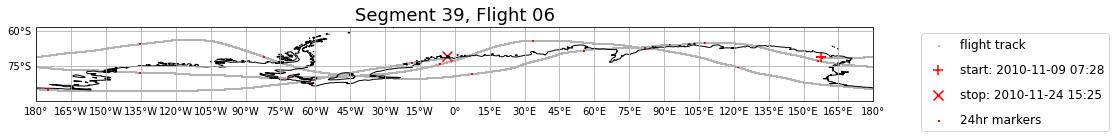

In [4]:
# Select one segment
segment_ids = flights.segment_id.unique()
segment = flights[flights.segment_id == 39] # the paper Concordiasi segment
#del flights

# Plot the segment
plt.figure(figsize=(15,15))
lat = np.array(segment.latitude.copy())
lon = np.array(segment.longitude.copy())
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([np.max([-180, np.min(lon)-5]), 
               np.min([180, np.max(lon)+5]), 
               np.max([-90, np.min(lat)-5]),
               np.min([90, np.max(lat)+5])], crs=ccrs.PlateCarree())
ax.coastlines(resolution='50m') # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,15))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,15))
plots = np.ndarray(shape=4,dtype='object')
plots[0] = plt.scatter(lon, lat, s=1, marker='s', color=[0.7,0.7,0.7], transform=ccrs.PlateCarree())
plots[1] = plt.scatter(lon[0], lat[0], s=100, marker='+', color='r', transform=ccrs.PlateCarree())
plots[2] = plt.scatter(lon[-1], lat[-1], s=100, marker='x', color='r', transform=ccrs.PlateCarree())
plots[3] = plt.scatter(lon[0:-1:2*60*24], lat[0:-1:2*60*24], s=1, marker='s', color='r', transform=ccrs.PlateCarree())
plt.title('Segment '+str(segment.segment_id.iloc[0])+', Flight '+str(segment.flight_id.iloc[0]), fontsize=18)
labels = np.ndarray(shape=4,dtype='object')
labels[0] = 'flight track'
labels[1] = 'start: '+str(segment.time.iloc[0].floor('min'))[:-3]
labels[2] = 'stop: '+str(segment.time.iloc[-1].floor('min'))[:-3]
labels[3] = '24hr markers'
leg = plt.legend(plots, labels, fontsize=12, bbox_to_anchor=(1.05, 1),
                     loc='upper left', labelspacing=1);
#plt.savefig('plots/temp1.png', format='png', bbox_inches='tight');

### Wavelet analysis function

In [5]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Prepare the segment for analysis

rho_bar: 0.09975842756333875
H: 6249.553601505985
Nref: 0.0258835622575204
Z_EDS: 0.3740440808989822


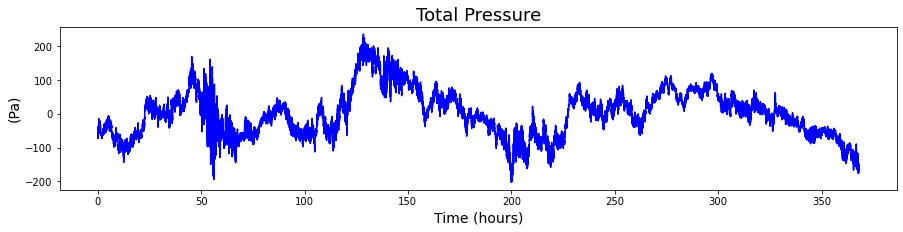

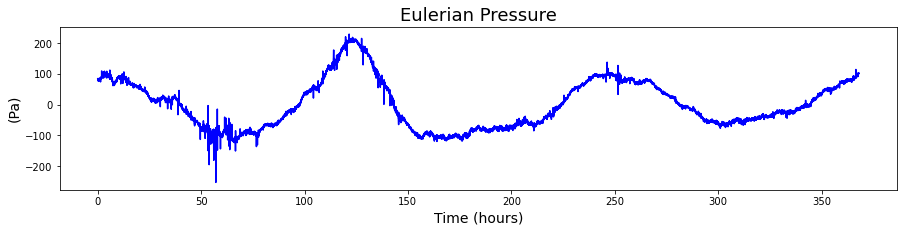

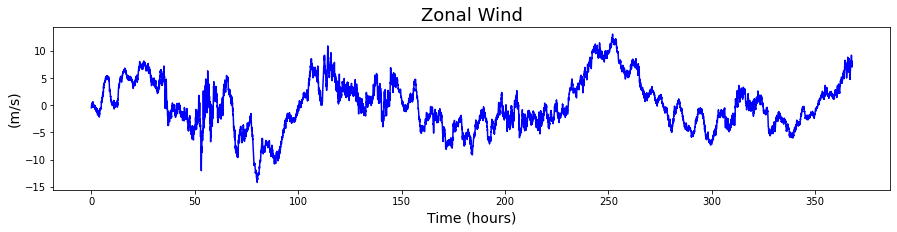

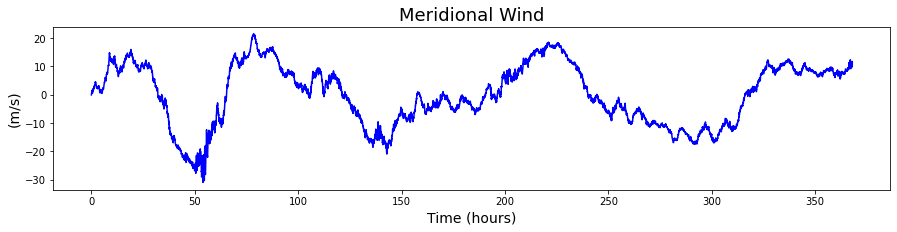

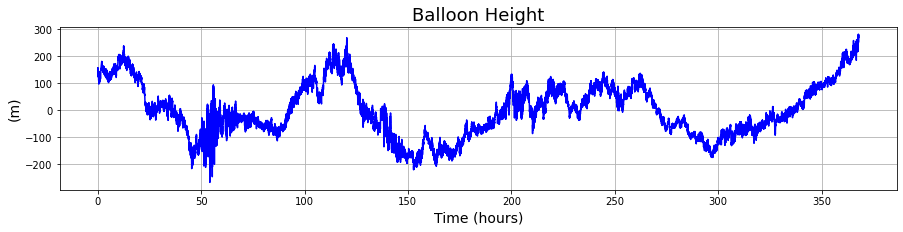

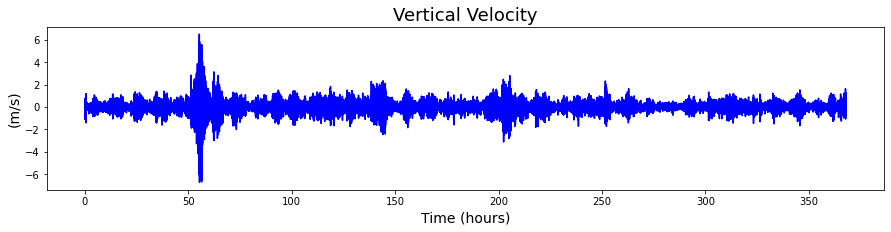

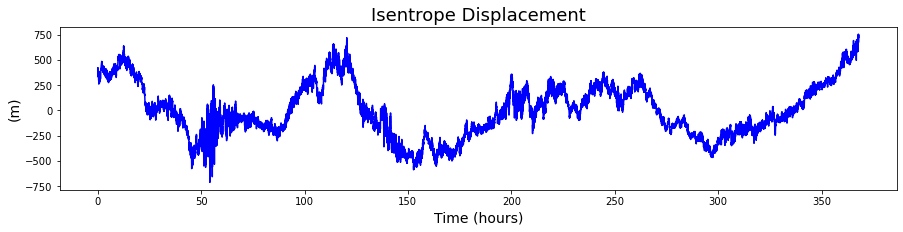

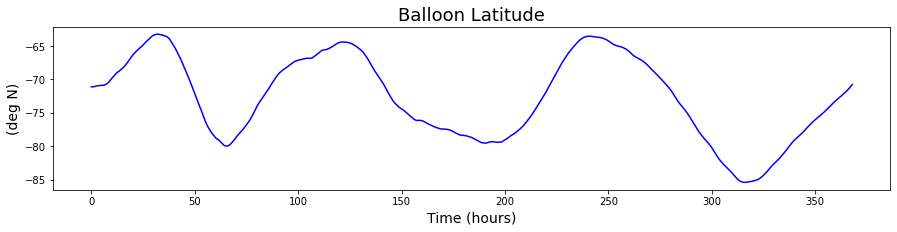

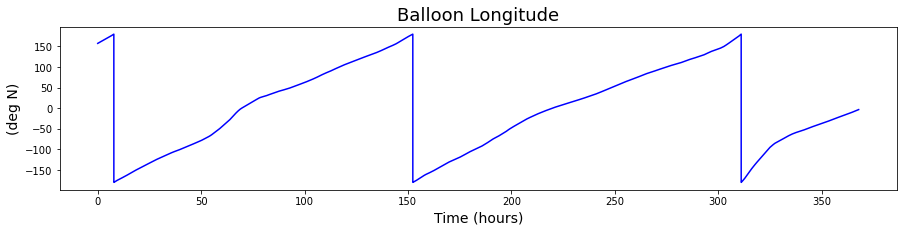

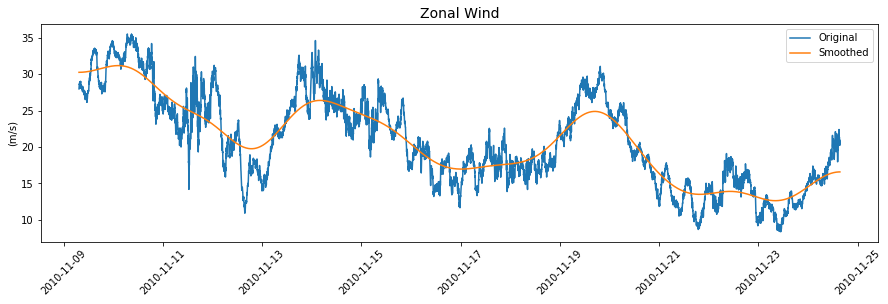

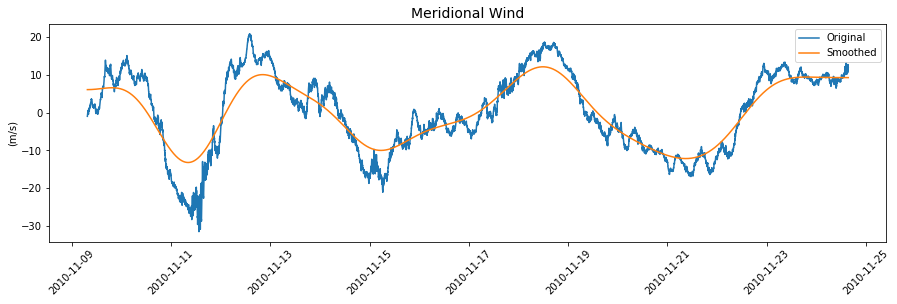

In [6]:
# Convert time to a numpy array with units of minutes
t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
N = np.size(t)
# Make other variables arrays
u = np.array(segment.wind_u)
v = np.array(segment.wind_v)
pt = 100*np.array(segment.pressure) # the Concordiasi data has pressure units of hPa; convert to Pa
altitude = np.array(segment.altitude)
balloon_lat = np.array(segment.latitude)
balloon_lon = np.array(segment.longitude)
T_env = np.array(segment.T_ERA5)
Nref = np.sqrt(np.array(segment.N2_ERA5))

# Calculate the environmental lapse rate
dTdz_env = (T_env/g)*(Nref**2) - (g/cp) # VH14 Eq. 6

# Calculate segment mean density. Because Loon temperature data is unreliable, use the
# environmental temperature from the COSMIC profiles
rho_bar = np.nanmean(pt/(R*T_env))

# Calculate the segment mean density scale height (CHECK THAT RT/g IS THE APPROPRIATE FORMULATION)
H = np.nanmean(R*T_env/g)

# Calculate the segment mean Coriolis parameter
f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180))
    
# Calculate the time series of the environmental buoyancy frequency and Z_EDS
Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
# As a start, to keep things simple, average them in time
Nref = np.nanmean(Nref)
Z_EDS = np.nanmean(Z_EDS)
print('rho_bar:', rho_bar)
print('H:', H)
print('Nref:', Nref)
print('Z_EDS:', Z_EDS)
    
# Calculate "smooth" velocities by using a Gaussian filter. The width (standard deviation) of the filter
# is determined by the longest period GW: either the Coriolis period or GW_PERIOD_MAX.
width = 2*Omega*np.sin(np.pi*np.max(np.abs(balloon_lat))/180) # Coriolis frequency, in 1/seconds
width = width/(2*np.pi) # convert from angular frequency to cyclic frequency
width = 1/(60*width) # period, in minutes
width = min(width, GW_PERIOD_MAX)/dt
u_smooth = gaussian_filter(u, sigma=width)
v_smooth = gaussian_filter(v, sigma=width)
    
# Create time series of anomalies by detrending
u = scipy.signal.detrend(u)
v = scipy.signal.detrend(v)
pt = scipy.signal.detrend(pt)
delta_b = scipy.signal.detrend(altitude)

# Back out the Eulerian pressure perturbation
p = pt + rho_bar*g*delta_b # VH14 Eq. 21
    
# Calculate delta_theta and w, using Z_EDS
delta_theta = delta_b/Z_EDS
w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
# Calculate the mean EKE and potential energy
EKE = 0.5*np.mean(u**2 + v**2 + w**2)
EKEh = 0.5*np.mean(u**2 + v**2)
EPE = 0.5*(Nref**2)*np.mean(delta_theta**2) # Eq. 2, Podglajen et al 2016

## PLOTS
plt.figure(figsize=(15,3))
plt.plot(t/60,pt,'b')
plt.title('Total Pressure', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(Pa)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,p,'b')
plt.title('Eulerian Pressure', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(Pa)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,u,'b')
plt.title('Zonal Wind', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(15,3))
plt.plot(t/60,v,'b')
plt.title('Meridional Wind', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,delta_b,'b')
plt.grid()
plt.title('Balloon Height', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m)', fontsize=14);
#plt.savefig('../plots/2014_segments/segment2498_delta_b.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(15,3))
plt.plot(t/60,w,'b')
plt.title('Vertical Velocity', fontsize=18)
#plt.ylim(-10, 10)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,delta_theta,'b')
plt.title('Isentrope Displacement', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(m)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,balloon_lat,'b')
plt.title('Balloon Latitude', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(deg N)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t/60,balloon_lon,'b')
plt.title('Balloon Longitude', fontsize=18)
plt.xlabel('Time (hours)', fontsize=14)
plt.ylabel('(deg N)', fontsize=14);

plt.figure(figsize = (15,4))
plt.plot(segment.time, segment.wind_u)
plt.plot(segment.time, u_smooth)
plt.xticks(rotation = 45)
plt.title('Zonal Wind',fontsize=14)
plt.ylabel('(m/s)')
plt.legend(['Original','Smoothed']);
#plt.savefig('plots/temp13.eps', format='eps', bbox_inches='tight');

plt.figure(figsize = (15,4))
plt.plot(segment.time, segment.wind_v)
plt.plot(segment.time, v_smooth)
plt.xticks(rotation = 45)
plt.title('Meridional Wind',fontsize=14)
plt.ylabel('(m/s)')
plt.legend(['Original','Smoothed']);

### Run the wavelet analysis

In [7]:
N = np.size(t)

# Time series' variance
std_w = np.std(w)
std_u = np.std(u)
std_v = np.std(v)
std_delta_theta = np.std(delta_theta)
var_w = std_w**2
var_u = std_u**2
var_v = std_v**2
var_delta_theta = std_delta_theta**2

# Run the wavelet analysis
print('W')
w_output = run_Morlet_CWT(w,dt,omega0,dj)
print('U')
u_output = run_Morlet_CWT(u,dt,omega0,dj)
print('V')
v_output = run_Morlet_CWT(v,dt,omega0,dj)
print('Altitude')
delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)

# Pull out a couple common variables to make some calculations easier
period = u_output.period; frequency = u_output.frequency; scale = u_output.s
N_pad = u_output.N_pad; coi = u_output.coi
C_delta = 0.5*(u_output.C_delta + v_output.C_delta)
nscales = np.size(scale)
var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)

# Tile a couple variables
scale_tiled_padded = np.tile(scale,(N + 2*N_pad,1)).swapaxes(0,1)
period_tiled_padded = np.tile(period,(N + 2*N_pad,1)).swapaxes(0,1)

# Calculate the EKE from the zero-padded wavelet output
print('Energy')
wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                            var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
# Calculate the EPE from the zero-padded wavelet output
wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
          np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
# Calculate total energy
wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep

# Calculate the total energies and test against the input
temp = (1/N)*np.sum(wave_Ekh, axis=1)
Ekh_total = dj*np.log(2)*np.nansum(temp*frequency)
temp = (1/N)*np.sum(wave_Ekv, axis=1)
Ekv_total = dj*np.log(2)*np.nansum(temp*frequency)
temp = (1/N)*np.sum(wave_Ep, axis=1)
Ep_total = dj*np.log(2)*np.nansum(temp*frequency)
temp = (1/N)*np.sum(wave_Etotal, axis=1)
Etotal_total = dj*np.log(2)*np.nansum(temp*frequency)
del wave_Ekv, wave_Ep
print()
temp = 0.5*np.nanmean(u**2 + v**2)
print('Ekh (m**2/s**2) in input time series, wavelet output:', temp, Ekh_total)
temp = 0.5*np.nanmean(w**2)
print('Ekv (m**2/s**2) in input time series, wavelet output:', temp, Ekv_total)
temp = 0.5*(Nref**2)*np.nanmean(delta_theta**2)
print('Ep (m**2/s**2) in input time series, wavelet output:', temp, Ep_total)
temp = 0.5*np.nanmean(u**2 + v**2 + w**2 + (Nref**2)*delta_theta**2)
print('Etotal (m**2/s**2) in input time series, wavelet output:', temp, Etotal_total)

W
U
V
Altitude
Energy

Ekh (m**2/s**2) in input time series, wavelet output: 67.51611794502998 67.51611794503
Ekv (m**2/s**2) in input time series, wavelet output: 0.11319488828487496 0.11319486141978588
Ep (m**2/s**2) in input time series, wavelet output: 23.141449801786326 23.141449801786294
Etotal (m**2/s**2) in input time series, wavelet output: 90.77076263510118 90.77076260823611


### Calculate u-w and v-w wavelet cross-spectra and the horizontal angle

In [8]:
# Calculate the cross-spectra of u, v and the vertical velocity
crossspec_u_w = w_output.wave*np.conj(u_output.wave) # this is the normalized spectrum
crossspec_v_w = w_output.wave*np.conj(v_output.wave) # this is the normalized spectrum

# Calculate C_delta so that the cross-spectral power is conserved, using the full
# u-w and v-w cross-spectra
uw_bar = np.nanmean(u*w)
vw_bar = np.nanmean(v*w)
temp = (std_u*std_w/var_ratio)*(dj*dt)* \
        np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
C_delta_uw = (1/N)*np.sum(temp)/uw_bar
temp = (std_v*std_w/var_ratio)*(dj*dt)* \
        np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)
C_delta_vw = (1/N)*np.sum(temp)/vw_bar
cross_total_power_u_w = (std_u*std_w/var_ratio)*(dj*dt/C_delta_uw)* \
                         np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
cross_total_power_v_w = (std_v*std_w/var_ratio)*(dj*dt/C_delta_vw)* \
                         np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)

# Print some 1-D statistics for validation
print('uw, vw C_delta:', C_delta_uw, C_delta_vw)
print('u, v, w, delta_theta C_delta:',
      u_output.C_delta, v_output.C_delta,w_output.C_delta, delta_theta_output.C_delta)
print('')
print('u, w covariance (m**2/s**2):')
print('from wavelets; mean(u*w)')
print((1/N)*cross_total_power_u_w.sum(),np.mean(u*w))
print('')
print('v, w covariance (m**2/s**2):')
print('GWs, from wavelets; all motions, from wavelets; mean(v*w)')
print((1/N)*cross_total_power_v_w.sum(),np.mean(v*w))
print('')

uw, vw C_delta: 0.574050331509733 0.5734364605203791
u, v, w, delta_theta C_delta: 0.5705237484102236 0.5699185604198878 0.5710768378675671 0.5656464756169481

u, w covariance (m**2/s**2):
from wavelets; mean(u*w)
-0.012680283838641457 -0.01268028383864146

v, w covariance (m**2/s**2):
GWs, from wavelets; all motions, from wavelets; mean(v*w)
0.024458527798025438 0.024458527798025424



### Calculate the total momentum flux wavelet

In [9]:
# Re-scale the total energy
# Calculate the scaling factor
balloon_lat_padded = np.nan*np.ones(N+2*N_pad)
balloon_lat_padded[N_pad:N+N_pad] = balloon_lat
balloon_lat_padded[:N_pad] = balloon_lat[0]
balloon_lat_padded[N+N_pad:] = balloon_lat[-1]
f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat_padded/180),(nscales,1))
frequency_rad = 2*np.pi*frequency/60
frequency_rad = np.tile(frequency_rad,(N + 2*N_pad,1)).swapaxes(0,1)
factor = (frequency_rad**2 - f_temp**2)/(Nref**2 - f_temp**2)
factor = factor*(Nref**2 - frequency_rad**2)/(Nref**2 - f_temp**2)
factor = rho_bar*np.sqrt(factor)
del f_temp, frequency_rad
# Do the scaling
wave_Etotal_scaled = factor*wave_Etotal

# Re-scale the u-w and v-w wavelet cross spectra and calculate the total momentum flux
temp = rho_bar*(std_w/var_ratio)*(dt)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
rescaled_ReUVW_total = temp*np.sqrt(np.real(std_u*crossspec_u_w/C_delta_uw)**2 + np.real(std_v*crossspec_v_w/C_delta_uw)**2)
global_ReUVW = (1/N)*np.sum(rescaled_ReUVW_total, axis=1)

# Identify wavelet coefficients with periods higher than GW_PERIOD_MAX
coeff_factor = 60*2*Omega*np.sin(np.pi*np.abs(balloon_lat_padded)/180) # Coriolis frequency in rad/min
coeff_factor = 2*np.pi/coeff_factor # period in minutes
coeff_factor = np.minimum(coeff_factor,GW_PERIOD_MAX)
coeff_factor = np.tile(coeff_factor,(nscales,1))
coeff_factor[coeff_factor < period_tiled_padded] = np.nan
# Identify wavelet coefficients with periods lower than GW_PERIOD_MIN
period_N = 2*np.pi/(60*Nref) # the buoyancy period
min_period = np.maximum(GW_PERIOD_MIN,period_N)
coeff_factor[period_tiled_padded < min_period] = np.nan
coeff_factor = coeff_factor/coeff_factor
# The total flux timeseries is equal to the integrals of the wavelet times frequency
# over dlog(frequency), which is dj*np.log(2) (log base e).
flux_total_Etotal = dj*np.log(2)*np.nansum(coeff_factor*wave_Etotal_scaled/period_tiled_padded, axis=0)
flux_total_ReUVW = dj*np.log(2)*np.nansum(coeff_factor*rescaled_ReUVW_total/period_tiled_padded, axis=0)

### Identify maxima in the total momentum flux wavelet and calculate their horizontal angle

In [10]:
# Find maxima by testing whether a value is greater than the eight others in its vicinity:
# (x-axis: wavelet time; y_axis: wavelet period)
#
#   1    2    3
#   4  value  5
#   6    7    8
#
# Maxima near the edges are ignored, because they are outside the time or period ranges
# of interest.
field = wave_Etotal_scaled.copy()
field_total_flux = flux_total_Etotal.copy()
#field = rescaled_ReUVW_total.copy()
#field_total_flux = flux_total_ReUVW.copy()
maxima = np.zeros(shape=(nscales-2, N+2*N_pad-2))
# Grid cell #1: up one in scale, back one time step
temp = field[2:,:-2]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #2: up one in scale, no time shift
temp = field[2:,1:-1]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #3: up one in scale, forward one time step
temp = field[2:,2:]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #4: no scale shift, back one time step
temp = field[1:-1,:-2]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #5: no scale shift, forward one time step
temp = field[1:-1,2:]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #6: down one in scale, back one time step
temp = field[:-2,:-2]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #7: down one in scale, no time shift
temp = field[:-2,1:-1]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
# Grid cell #8: down one in scale, forward one time step
temp = field[:-2,2:]
maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
del temp
# There is a maximum when maxima = 8:
maxima[maxima < 8] = 0
maxima[maxima == 8] = 1
# Change the shape of the maxima so that it has the same dimensions as wavelet
# output (nscales,N+2*N_pad)
temp = maxima.copy()
maxima = np.zeros(shape=(nscales, N+2*N_pad))
maxima[1:-1,1:-1] = temp
del temp
# Eliminate maxima in the zero padding regions
maxima[:,:N_pad] = 0
maxima[:,N+N_pad:] = 0
# Eliminate maxima outside the GW frequency range
maxima[np.isnan(coeff_factor) == True] = 0
# Eliminate maxima inside the COI
temp = np.zeros(N+2*N_pad)
temp[N_pad:N+N_pad] = coi
temp = np.tile(temp,(nscales,1))
maxima[period_tiled_padded > temp] = 0
del temp
# Eliminate maxima when the frequency-integrated GW momentum flux is below
# a threshold
temp = np.tile(1000*field_total_flux,(nscales,1))
maxima[temp < FLUX_THRESHOLD] = 0
del temp
n_maxima = int(np.sum(maxima))

# Compile the maxima into lists of periods and times
temp_time = np.tile(segment.time.iloc[0],(N+2*N_pad))
temp_time[N_pad:N+N_pad] = segment.time
temp_time[N+N_pad:] = segment.time.iloc[-1]
temp_time = np.tile(temp_time,(nscales,1))
maxima_time = temp_time[maxima == 1]
maxima_period = period_tiled_padded[maxima == 1]
maxima_period_ind = np.tile(np.arange(nscales),(N+2*N_pad,1)).swapaxes(0,1)
maxima_time_ind = np.tile(np.arange(N+2*N_pad), (nscales,1))
maxima_period_ind = maxima_period_ind[maxima == 1]
maxima_time_ind = maxima_time_ind[maxima == 1]
del temp_time

# Calculate the horizontal angle as the acrtangent of x- and y-fields averaged
# over a stencil around the maxima
x_field = np.real(std_u*crossspec_u_w/C_delta_uw)
y_field = np.real(std_v*crossspec_v_w/C_delta_vw)
maxima_theta_h = np.nan*np.ones(n_maxima)
for i in np.arange(n_maxima):
    
    # Retrive the x- and y-fields over the stencil
    period_ind = maxima_period_ind[i] - int((STENCIL_DIM-1)/2) + np.arange(STENCIL_DIM)
    time_ind = maxima_time_ind[i] - int((STENCIL_DIM-1)/2) + np.arange(STENCIL_DIM)
    x_field_temp = x_field[period_ind,time_ind]
    y_field_temp = y_field[period_ind,time_ind]
    field_temp = field[period_ind,time_ind]
    
    # Normalize to unit length and weight by the magnitude of the field
    temp = np.sqrt(x_field_temp**2 + y_field_temp**2)
    x_field_temp = x_field_temp*field_temp/temp
    y_field_temp = y_field_temp*field_temp/temp
    
    # Average their values, weighting them by 1/scale (could weight by frequency)
    # and take their arctangent
    weighting = np.tile(1/scale[period_ind],(STENCIL_DIM,1)).swapaxes(0,1)
    temp = x_field_temp/x_field_temp # in case there's NaNs
    x_field_temp = np.nansum(temp*x_field_temp*weighting)/np.nansum(temp*weighting)
    temp = y_field_temp/y_field_temp # in case there's NaNs
    y_field_temp = np.nansum(temp*y_field_temp*weighting)/np.nansum(temp*weighting)
    maxima_theta_h[i] = 180*np.arctan2(y_field_temp,x_field_temp)/np.pi

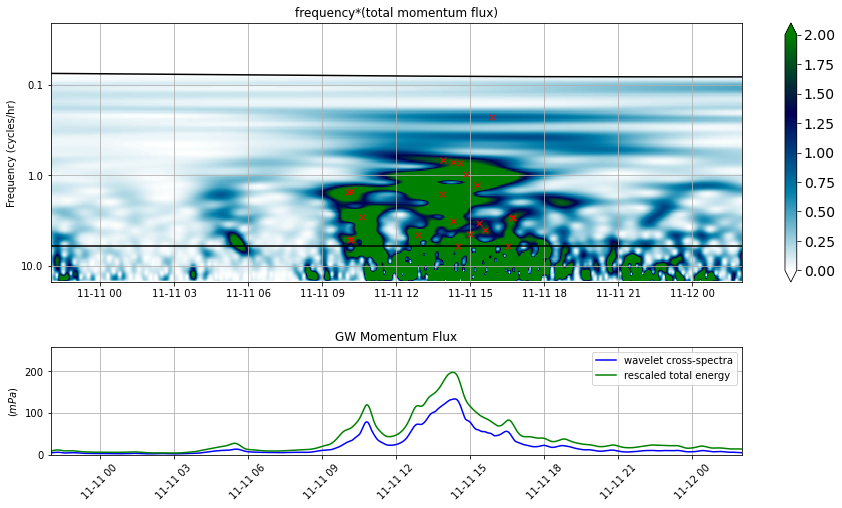

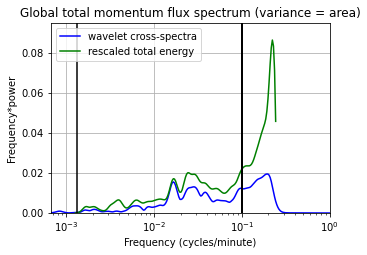

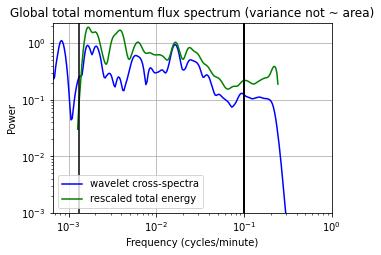

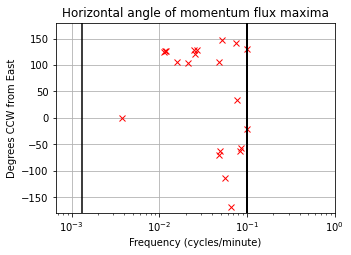

In [11]:
# Narrow down the time range, for plotting
time_start = pd.Timestamp('2010-11-10 22:00') # Flight 04 Antarctic Peninsula crossing
time_stop = pd.Timestamp('2010-11-12 02:00') # Flight 04 Antarctic Peninsula crossing
temp_ind = np.arange(N)
temp_ind = temp_ind[segment.time >= time_start]
ind_start = temp_ind[0] + N_pad
temp_ind = np.arange(N)
temp_ind = temp_ind[segment.time <= time_stop]
ind_stop = temp_ind[-1] + N_pad

# Select the maxima in this time window
maxima_period = maxima_period[maxima_time >= time_start]
maxima_theta_h = maxima_theta_h[maxima_time >= time_start]
maxima_time = maxima_time[maxima_time >= time_start]
maxima_period = maxima_period[maxima_time <= time_stop]
maxima_theta_h = maxima_theta_h[maxima_time <= time_stop]
maxima_time = maxima_time[maxima_time <= time_stop]

# Minimum and maximum period, for plotting
min_period = GW_PERIOD_MIN*np.ones(ind_stop - ind_start)
period_f = 2*Omega*np.sin(np.pi*balloon_lat_padded[ind_start:ind_stop]/180)
period_f = np.abs(2*np.pi/(60*period_f))
max_period = np.minimum(GW_PERIOD_MAX,period_f)

# Plot the field and the maxima
fig = plt.figure(figsize=(12,6))
ax3 = plt.axes([0, 0.4, 1, 0.6])
temp = field[:,ind_start:ind_stop].copy()
freqs_temp = np.tile(60*frequency,(ind_stop-ind_start,1)).swapaxes(0,1)
fig3 = ax3.pcolormesh(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60*frequency),
                      freqs_temp*temp,vmin=0,vmax=2,cmap='ocean_r')
cbar = fig.colorbar(fig3,extend = 'both')
cbar.ax.tick_params(labelsize=14)
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/min_period),'k')
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/max_period),'k')
ax3.plot(maxima_time,np.log10(60/maxima_period),'rx')
ax3.grid()
ax3.set_title('frequency*(total momentum flux)')
ax3.set_ylabel('Frequency (cycles/hr)')
Yticks = 10**np.arange(np.ceil(np.log10(60*frequency.min())),np.ceil(np.log10(60*frequency.max())))
ax3.set_yticks(np.log10(Yticks))
ax3.set_yticklabels(Yticks)
#ax3.set_xticklabels([])
ax3.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax3.set_ylim(np.log10(60/4),np.log10(1/(2*24)));

# Plot the momentum flux time series
ax1 = plt.axes([0, 0, 0.8, 0.25])
ax1.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad], 1000*flux_total_ReUVW[ind_start:ind_stop], 'b')
ax1.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad], 1000*flux_total_Etotal[ind_start:ind_stop], 'g')
ax1.grid()
ax1.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax1.set_ylim(0,1.1*1000*np.nanmax(flux_total_Etotal))
ax1.tick_params('x',rotation=45)
ax1.set_title('GW Momentum Flux')
ax1.set_ylabel('$(mPa)$')
ax1.legend(['wavelet cross-spectra','rescaled total energy']);
#fig.savefig('../plots/temp2.png', format='png', bbox_inches='tight');

# Plot the global spectra
# Power*frequency vs. log(frequency) (This method has variance ~ area)
plt.figure(figsize=(5,3.5))
global_total_flux_temp = np.nanmean(rescaled_ReUVW_total[:,ind_start:ind_stop], axis=1)
global_Etotal_temp_scaled = np.nanmean(wave_Etotal_scaled[:,ind_start:ind_stop], axis=1)
plt.plot(frequency, frequency*global_total_flux_temp, 'b')
plt.plot(frequency, frequency*global_Etotal_temp_scaled, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.1*np.nanmax(frequency*global_Etotal_temp_scaled)],'k')
plt.plot([1/min_period, 1/min_period], [0, 1.1*np.nanmax(frequency*global_Etotal_temp_scaled)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(0,1.1*np.nanmax(frequency*global_Etotal_temp_scaled))
plt.xscale('log')
plt.title('Global total momentum flux spectrum (variance = area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Frequency*power')
plt.legend(['wavelet cross-spectra','rescaled total energy']);
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');

# Plot the global spectra
# log(power) vs. log(frequency) (This method does not have variance ~ area)
plt.figure(figsize=(5,3.5))
global_total_flux_temp = np.nanmean(rescaled_ReUVW_total[:,ind_start:ind_stop], axis=1)
global_Etotal_temp_scaled = np.nanmean(wave_Etotal_scaled[:,ind_start:ind_stop], axis=1)
plt.plot(frequency, global_total_flux_temp, 'b')
plt.plot(frequency, global_Etotal_temp_scaled, 'g')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [0, 1.2*np.nanmax(global_Etotal_temp_scaled)],'k')
plt.plot([1/min_period, 1/min_period], [0, 1.2*np.nanmax(global_Etotal_temp_scaled)],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(1E-3,1.2*np.nanmax(global_Etotal_temp_scaled))
plt.xscale('log')
plt.yscale('log')
plt.title('Global total momentum flux spectrum (variance not ~ area)')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Power')
plt.legend(['wavelet cross-spectra','rescaled total energy']);
#plt.savefig('../plots/temp4.pdf', format='pdf', bbox_inches='tight');

# Plot the maxima horizontal angle
plt.figure(figsize=(5,3.5))
plt.plot(1/maxima_period, maxima_theta_h, 'rx')
plt.plot([np.abs(60*f/(2*np.pi)), np.abs(60*f/(2*np.pi))], [-180, 180],'k')
plt.plot([1/min_period, 1/min_period], [-180, 180],'k')
plt.grid()
plt.xlim(np.abs(60*f/(2*np.pi))/2,frequency[0])
plt.ylim(-180,180)
plt.xscale('log')
plt.title('Horizontal angle of momentum flux maxima')
plt.xlabel('Frequency (cycles/minute)')
plt.ylabel('Degrees CCW from East');
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');

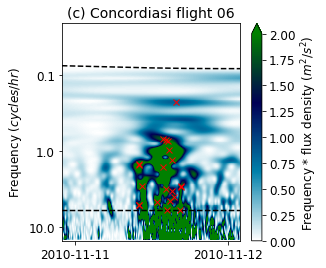

In [12]:
# Plot the field and the maxima
fig, ax3 = plt.subplots(figsize=(4,4))
temp = field[:,ind_start:ind_stop].copy()
freqs_temp = np.tile(60*frequency,(ind_stop-ind_start,1)).swapaxes(0,1)
fig3 = ax3.pcolormesh(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60*frequency),
                      freqs_temp*temp,vmin=0,vmax=2,cmap='ocean_r')
cbar = fig.colorbar(fig3,extend = 'max')
cbar.ax.tick_params(labelsize=12)
cbar.set_label('Frequency * flux density $(m^2/s^2)$', fontsize=12)
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/min_period),'--k')
ax3.plot(segment.time.iloc[ind_start-N_pad:ind_stop-N_pad],np.log10(60/max_period),'--k')
ax3.plot(maxima_time,np.log10(60/maxima_period),'rx')
ax3.set_title('(c) Concordiasi flight 06', fontsize=14)
ax3.set_ylabel('Frequency $(cycles/hr)$',fontsize=12)
myFmt = DateFormatter("%d")
ax3.xaxis.set_major_formatter(myFmt)
temp = segment.iloc[ind_start-N_pad:ind_stop-N_pad]
temp = temp['time'].dt.date
temp = temp.unique()
Xticks = temp
Yticks = 10**np.arange(np.ceil(np.log10(60*frequency.min())),np.ceil(np.log10(60*frequency.max())))
ax3.set_xticks(Xticks)
ax3.set_yticks(np.log10(Yticks))
ax3.set_xticklabels(Xticks, fontsize=12)
ax3.set_yticklabels(Yticks, fontsize=12)
ax3.set_xlim(segment.time.iloc[ind_start-N_pad],segment.time.iloc[ind_stop-N_pad])
ax3.set_ylim(np.log10(60/4),np.log10(1/(2*24)));
#plt.savefig('../plots/temp2.pdf', format='pdf', bbox_inches='tight');
#plt.savefig('../plots/temp2.png', format='png', bbox_inches='tight');

In [18]:
# Save the maxima period and theta_h
data = [maxima_period,
        maxima_theta_h]
np.savez('Concordiasi_maxima_flight06_segment39_20mPaThresh_fluxEtot.npz', *data) 

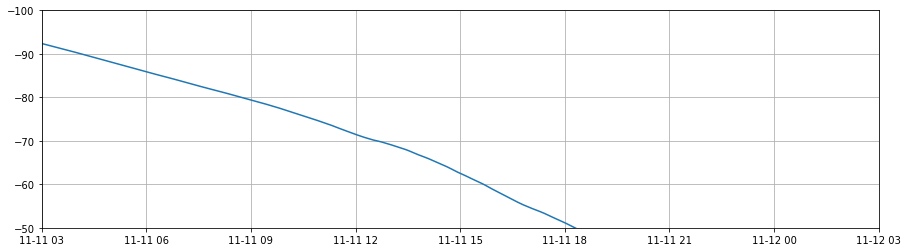

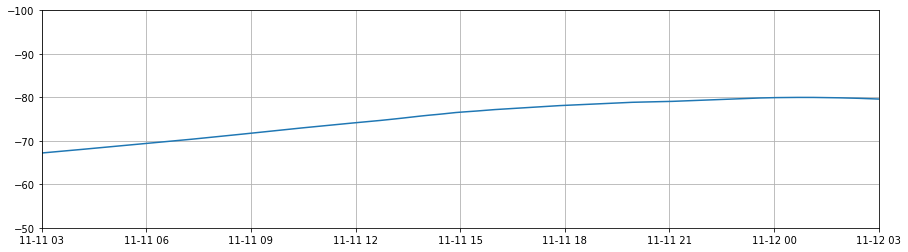

In [44]:
plt.figure(figsize=(15,4))
plt.plot(segment.time,segment.longitude)
plt.grid()
plt.xlim(time_start,time_stop)
plt.ylim(-50,-100);

plt.figure(figsize=(15,4))
plt.plot(segment.time,segment.latitude)
plt.grid()
plt.xlim(time_start,time_stop)
plt.ylim(-50,-100);